# Player Archetype Analysis; Feature Preprocessing (Transformation & Scaling) [Milestone 3.1]

**Project Objective**:
Gather football player and team performance data across Europe's top 5 leagues to create a scouting dashboard that leverages unsupervised Machine Learning to identify statistical profiles ("player archetypes") and uncover comparable or undervalued talents.

### Milestone 3.1 Objectives:
1. Separate descriptive columns (`player_identifier`, `Player`, `Nation`, `Age`, `Pos`, `Primary_Pos`, `Squad`, `Comp`, league playing percentages) from the numeric performance feature matrix.
2. Address heavy skewed and zero-inflated distributions via Yeo-Johnson power transformations and justified (via domain knowledge) custom weighting.
3. Standardise/scale features using `StandardScaler` and evaluate against `RobustScaler`.

## Setup

In [11]:
import warnings
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import PowerTransformer, RobustScaler, StandardScaler

# Add repo root to locate data directory
repo_root = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()

PRIMARY_POS_ORDER = ['GK', 'DF', 'MF', 'FW']

warnings.filterwarnings('ignore', category=UserWarning)
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 10

### Ingesting the Cleaned Featureset
Import `player_featureset.csv`, which has previously been processed by:
- Goalkeepers filtered out.
- Min 600 minutes played per club filter.
- Multi-club players aggregated.
- Metrics normalised to per-90 (with a `_p90` suffix).
- Redundant within-group features pruned.

In [12]:
featureset_path = repo_root / 'data' / 'processed' / 'player_featureset.csv'
df = pd.read_csv(featureset_path)

print(f"{df.shape[0]} players, {df.shape[1]} total columns")
print(f"Missing values: {df.isna().sum().sum()}")
df.sample(10)

1737 players, 120 total columns
Missing values: 0


,player_identifier,Player,Nation,Age,Pos,Primary_Pos,Num_Pos,Squad,Comp,passing_foot_pref,...,Car3rd_p90,CPA_p90,CarMis_p90,CarDis_p90,Fld_p90,CarProg%,CrdY_p90,CrdR_p90,2CrdY_p90,Fls_p90
944,Liam Cooper_SCO_1991,Liam Cooper,SCO,30,DF,DF,1,Leeds United,Premier League,prefers left foot,...,0.099228,0.000000,0.297685,0.148842,0.644983,0.026316,0.248071,0.000000,0.0,0.942668
790,Jonas Wind_DEN_1999,Jonas Wind,DEN,23,"FW, MF",FW,2,Wolfsburg,Bundesliga,prefers right foot,...,0.762712,0.610169,2.135593,1.449153,2.593220,0.111842,0.000000,0.000000,0.0,1.220339
92,Amir Rrahmani_KVX_1994,Amir Rrahmani,KVX,28,DF,DF,1,Napoli,Serie A,heavily prefers right foot,...,0.338230,0.000000,0.153741,0.276734,0.768705,0.056250,0.153741,0.000000,0.0,0.768705
224,Bryan Cristante_ITA_1995,Bryan Cristante,ITA,27,MF,MF,1,Roma,Serie A,prefers right foot,...,1.277072,0.033607,0.235250,0.907394,0.604929,0.112928,0.302465,0.000000,0.0,1.613144
739,Jeong Woo-yeong_KOR_1999,Jeong Woo-yeong,KOR,22,"FW, MF",FW,2,Freiburg,Bundesliga,prefers right foot,...,1.161616,0.606061,1.363636,1.212121,0.959596,0.125000,0.050505,0.000000,0.0,0.505051
671,Ivan Ili?_SRB_2001,Ivan Ili?,SRB,21,MF,MF,1,Hellas Verona,Serie A,heavily prefers left foot,...,1.674584,0.142518,1.389549,0.961995,1.247031,0.118888,0.178147,0.035629,0.0,1.710214
1192,Moises Caicedo_ECU_2001,Moises Caicedo,ECU,20,MF,MF,1,Brighton,Premier League,prefers right foot,...,1.363636,0.272727,0.954545,0.954545,2.181818,0.095890,0.272727,0.000000,0.0,1.227273
1042,Marc-Oliver Kempf_GER_1995,Marc-Oliver Kempf,GER,27,DF,DF,1,"Hertha BSC, Stuttgart",Bundesliga,prefers left foot,...,0.713908,0.047594,0.571126,0.333157,0.999471,0.074074,0.142782,0.047594,0.0,1.332628
1325,Pathe Ciss_SEN_1994,Pathe Ciss,SEN,28,MF,MF,1,Rayo Vallecano,La Liga,heavily prefers right foot,...,0.984503,0.000000,0.410210,0.902461,1.148587,0.090000,0.410210,0.000000,0.0,1.640839
1224,Nathan Tella_ENG_1999,Nathan Tella,ENG,22,"FW, MF",MF,2,Southampton,Premier League,prefers right foot,...,1.679104,0.783582,4.925373,2.798507,2.574627,0.129555,0.223881,0.000000,0.0,2.350746


## Identify Modelling Features

The below features are purely for post-modelling analysis and dashboard filtering:
   - Player identity: `player_identifier`, `Player`, `Nation`, `Age`.
   - Positional assignments: `Pos`, `Primary_Pos`, `Num_Pos`.
   - Team & Competition context: `Squad`, `Comp`.
   - Categorical / engineered preferences: `passing_foot_pref`, `signed_preference_score`.
   - League minutes share: `Premier League_pct_mins`, `Ligue 1_pct_mins`, `Bundesliga_pct_mins`, `Serie A_pct_mins`, `La Liga_pct_mins`.

The rest are the performance metrics to be passed into the model.

In [13]:
LEAGUE_PCT_MINS_COLS = [
    'Premier League_pct_mins',
    'Ligue 1_pct_mins',
    'Bundesliga_pct_mins',
    'Serie A_pct_mins',
    'La Liga_pct_mins',
]

DESCRIPTIVE_COLS = [
    'player_identifier',
    'Player',
    'Nation',
    'Age',
    'Pos',
    'Primary_Pos',
    'Num_Pos',
    'Squad',
    'Comp',
    'passing_foot_pref',
    'signed_preference_score',
    *LEAGUE_PCT_MINS_COLS,
]


def separate_features_and_metadata(
    df: pd.DataFrame,
    metadata_cols: list[str] | None = None,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Separates metadata/descriptive columns from numeric performance features."""
    if metadata_cols is None:
        metadata_cols = DESCRIPTIVE_COLS

    present_meta = [col for col in metadata_cols if col in df.columns]
    feature_cols = [col for col in df.columns if col not in present_meta]

    metadata_df = df[present_meta].copy()
    X = df[feature_cols].copy()

    # Ensure all remaining features are numeric
    non_numeric = X.select_dtypes(exclude=[np.number]).columns.tolist()
    if non_numeric:
        raise ValueError(f"Non-numeric columns found in feature matrix: {non_numeric}")

    return metadata_df, X


metadata_df, X_raw = separate_features_and_metadata(df, metadata_cols=DESCRIPTIVE_COLS)

print(f"Metadata Matrix Shape:\n{metadata_df.shape}")
print(f"Numeric Feature Matrix Shape:\n{X_raw.shape}")

# Ensure only numeric cols are present
non_numeric_cols = X_raw.select_dtypes(exclude=[np.number]).columns.tolist()
if non_numeric_cols:
    raise ValueError(f"Non-numeric columns in feature matrix: {non_numeric_cols}")

# Preview metadata columns
print("\nDescriptive metadata columns:")
print(metadata_df.columns.tolist())
metadata_df.head(3)

Metadata Matrix Shape:
(1737, 10)
Numeric Feature Matrix Shape:
(1737, 110)

Descriptive metadata columns:
['player_identifier', 'Player', 'Nation', 'Age', 'Pos', 'Primary_Pos', 'Num_Pos', 'Squad', 'Comp', 'passing_foot_pref']


,player_identifier,Player,Nation,Age,Pos,Primary_Pos,Num_Pos,Squad,Comp,passing_foot_pref
0,Aaron Cresswell_ENG_1989,Aaron Cresswell,ENG,32,DF,DF,1,West Ham,Premier League,heavily prefers left foot
1,Aaron Hickey_SCO_2002,Aaron Hickey,SCO,19,DF,DF,1,Bologna,Serie A,indifferent
2,Aaron Lennon_ENG_1987,Aaron Lennon,ENG,35,MF,MF,1,Burnley,Premier League,heavily prefers right foot


## 3. Skewness Diagnosis & Distribution Analysis

EDA revealed that many of these metrics are heavily right skewed, and sometimes zero-inflated. For example, strikers score the majority of goals, while defenders make the majority of clearances, and only a small number of players regularly take set pieces. Other events are generally rare, such as red cards.

These heavily skewed distributions can dominate the variance in dimension reduction and the distances used to calculate clusters.

We can quantify skew (using the Fisher-Pearson skewness coefficient) to classify the level of skew across each feature. High skew may require transforming.

In [14]:
skewness_series = X_raw.skew()
abs_skewness = skewness_series.abs()

skew_summary = pd.DataFrame({
    'Metric': skewness_series.index,
    'Skewness': skewness_series.values,
    'Abs_Skewness': abs_skewness.values,
}).sort_values('Abs_Skewness', ascending=False)

symmetric_count = (abs_skewness <= 0.5).sum()
moderate_count = ((abs_skewness > 0.5) & (abs_skewness <= 1.0)).sum()
high_count = ((abs_skewness > 1.0) & (abs_skewness <= 2.0)).sum()
severe_count = (abs_skewness > 2.0).sum()

print("=== Feature Skewness Classification ===")
print(f"Approximately Symmetric (|skew| <= 0.5):        {symmetric_count:2d} features ({symmetric_count/len(X_raw.columns)*100:5.1f}%)")
print(f"Moderately Skewed        (0.5 < |skew| <= 1.0): {moderate_count:2d} features ({moderate_count/len(X_raw.columns)*100:5.1f}%)")
print(f"Highly Skewed            (1.0 < |skew| <= 2.0): {high_count:2d} features ({high_count/len(X_raw.columns)*100:5.1f}%)")
print(f"Severely Skewed / Rare   (|skew| > 2.0):        {severe_count:2d} features ({severe_count/len(X_raw.columns)*100:5.1f}%)")

=== Feature Skewness Classification ===
Approximately Symmetric (|skew| <= 0.5):        26 features ( 23.6%)
Moderately Skewed        (0.5 < |skew| <= 1.0): 38 features ( 34.5%)
Highly Skewed            (1.0 < |skew| <= 2.0): 25 features ( 22.7%)
Severely Skewed / Rare   (|skew| > 2.0):        21 features ( 19.1%)


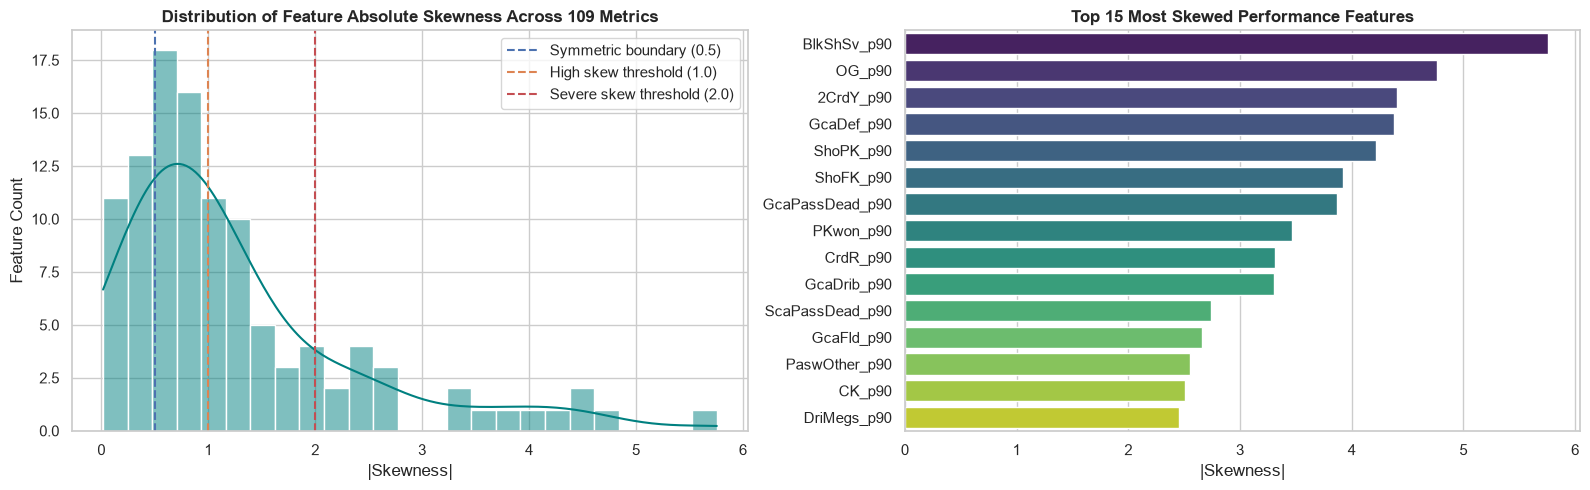

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Distribution of absolute skewness
sns.histplot(abs_skewness, bins=25, kde=True, color='teal', ax=axes[0])
axes[0].axvline(0.5, color='#4C72B0', linestyle='--', linewidth=1.5, label='Symmetric boundary (0.5)')
axes[0].axvline(1.0, color='#DD8452', linestyle='--', linewidth=1.5, label='High skew threshold (1.0)')
axes[0].axvline(2.0, color='#C44E52', linestyle='--', linewidth=1.5, label='Severe skew threshold (2.0)')
axes[0].set_title('Distribution of Feature Absolute Skewness Across 109 Metrics', fontsize=12, fontweight='bold')
axes[0].set_xlabel('|Skewness|')
axes[0].set_ylabel('Feature Count')
axes[0].legend()

# Top 15 most skewed features
top_15_skewed = skew_summary.head(15)
sns.barplot(data=top_15_skewed, x='Abs_Skewness', y='Metric', hue='Metric', palette='viridis', legend=False, ax=axes[1])
axes[1].set_title('Top 15 Most Skewed Performance Features', fontsize=12, fontweight='bold')
axes[1].set_xlabel('|Skewness|')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()


46 (41.8%) of the features are heavily skewed and will require transformation, with the majority of these being low count `_p90` metrics

## 4. Transformations

There are many ways to transform the data, but three of them are:
- **Box-Cox**; Requires strictly positive values, which cannot handle the fairly common 0 values in this data.
- **Log(x + 1)**: Unsuitable due to the fractional p90 values in the data, which will be unevenly compressed by the transformation.
- **Yeo-Johnson**: Supports <=0 values (such as `forward_pressing_index` and `forward_touch_index`), so is the most appropriate. It also has the benefit of being flexible, calculating a $\lambda$ value for each feature via Maximum Likelihood Estimation, which in turn applies a different transformation depending on the shape & skew of the data.

The latter will therefore be applied to all features exceeding the $|skew| > 1.0$ threshold.

In [16]:
def detect_skewed_features(
    X: pd.DataFrame,
    threshold: float = 1.0,
) -> list[str]:
    """Identifies features whose absolute skewness exceeds a given threshold."""
    skews = X.skew().abs()
    return skews[skews > threshold].index.tolist()


def power_transform_features(
    X: pd.DataFrame,
    columns: list[str] | None = None,
    method: str = 'yeo-johnson',
    skew_threshold: float = 1.0,
) -> tuple[pd.DataFrame, PowerTransformer]:
    """Applies power transformation to reduce skewness and stabilise variance."""
    if columns is None:
        columns = detect_skewed_features(X, threshold=skew_threshold)

    X_trans = X.copy()
    if not columns:
        transformer = PowerTransformer(method=method, standardize=False)
        return X_trans, transformer

    transformer = PowerTransformer(method=method, standardize=False)
    transformed_vals = transformer.fit_transform(X[columns])
    X_trans[columns] = transformed_vals

    return X_trans, transformer


skewed_cols = detect_skewed_features(X_raw, threshold=1.0)
print(f"Applying Yeo-Johnson transformation to {len(skewed_cols)} skewed features...")

X_transformed, pt = power_transform_features(X_raw, columns=skewed_cols, method='yeo-johnson')

skew_comparison = pd.DataFrame({
    'Metric': skewed_cols,
    'Raw_Skew': X_raw[skewed_cols].skew().values,
    'Transformed_Skew': X_transformed[skewed_cols].skew().values,
    'Fitted_Lambda': pt.lambdas_,
})
skew_comparison['Abs_Reduction'] = skew_comparison['Raw_Skew'].abs() - skew_comparison['Transformed_Skew'].abs()
skew_comparison = skew_comparison.sort_values(by='Raw_Skew', key=abs, ascending=False)

print(f"Mean absolute skewness across transformed features:")
print(f"  Raw:         {X_raw[skewed_cols].skew().abs().mean():.3f}")
print(f"  Transformed: {X_transformed[skewed_cols].skew().abs().mean():.3f}")

skew_comparison.head(15)

Applying Yeo-Johnson transformation to 46 skewed features...
Mean absolute skewness across transformed features:
  Raw:         2.222
  Transformed: 0.725


,Metric,Raw_Skew,Transformed_Skew,Fitted_Lambda,Abs_Reduction
31,BlkShSv_p90,5.755743,2.404806,-153.293957,3.350938
35,OG_p90,4.762056,3.332284,-250.333499,1.429772
45,2CrdY_p90,4.405376,3.041800,-230.823908,1.363576
13,GcaDef_p90,4.380927,2.720055,-193.744969,1.660872
16,ShoPK_p90,4.221143,2.451184,-90.570941,1.769959
15,ShoFK_p90,3.924373,1.270152,-21.444061,2.654221
18,GcaPassDead_p90,3.871277,1.829355,-68.592427,2.041922
14,PKwon_p90,3.465834,1.801632,-88.414116,1.664202
44,CrdR_p90,3.313461,1.880571,-106.170534,1.432889
10,GcaDrib_p90,3.304493,1.648192,-71.643388,1.656300


In [17]:
skewness_series = X_transformed.skew()
abs_skewness = skewness_series.abs()

skew_summary = pd.DataFrame({
    'Metric': skewness_series.index,
    'Skewness': skewness_series.values,
    'Abs_Skewness': abs_skewness.values,
}).sort_values('Abs_Skewness', ascending=False)

symmetric_count = (abs_skewness <= 0.5).sum()
moderate_count = ((abs_skewness > 0.5) & (abs_skewness <= 1.0)).sum()
high_count = ((abs_skewness > 1.0) & (abs_skewness <= 2.0)).sum()
severe_count = (abs_skewness > 2.0).sum()

still_skewed_features = list(skew_summary[skew_summary.Abs_Skewness > 1].Metric)

print("=== Feature Skewness Classification ===")
print(f"Approximately Symmetric (|skew| <= 0.5):        {symmetric_count:2d} features ({symmetric_count/len(X_transformed.columns)*100:5.1f}%)")
print(f"Moderately Skewed        (0.5 < |skew| <= 1.0): {moderate_count:2d} features ({moderate_count/len(X_transformed.columns)*100:5.1f}%)")
print(f"Highly Skewed            (1.0 < |skew| <= 2.0): {high_count:2d} features ({high_count/len(X_transformed.columns)*100:5.1f}%)")
print(f"Severely Skewed / Rare   (|skew| > 2.0):        {severe_count:2d} features ({severe_count/len(X_transformed.columns)*100:5.1f}%)")

print(f"\nStill Skewed Features  (1.0 < |skew|): [{len(still_skewed_features)} features]\n        {still_skewed_features}")


=== Feature Skewness Classification ===
Approximately Symmetric (|skew| <= 0.5):        56 features ( 50.9%)
Moderately Skewed        (0.5 < |skew| <= 1.0): 41 features ( 37.3%)
Highly Skewed            (1.0 < |skew| <= 2.0):  8 features (  7.3%)
Severely Skewed / Rare   (|skew| > 2.0):         5 features (  4.5%)

Still Skewed Features  (1.0 < |skew|): [13 features]
        ['OG_p90', '2CrdY_p90', 'GcaDef_p90', 'ShoPK_p90', 'BlkShSv_p90', 'CrdR_p90', 'GcaPassDead_p90', 'PKwon_p90', 'GcaDrib_p90', 'PKcon_p90', 'GcaFld_p90', 'ShoFK_p90', 'Err_p90']


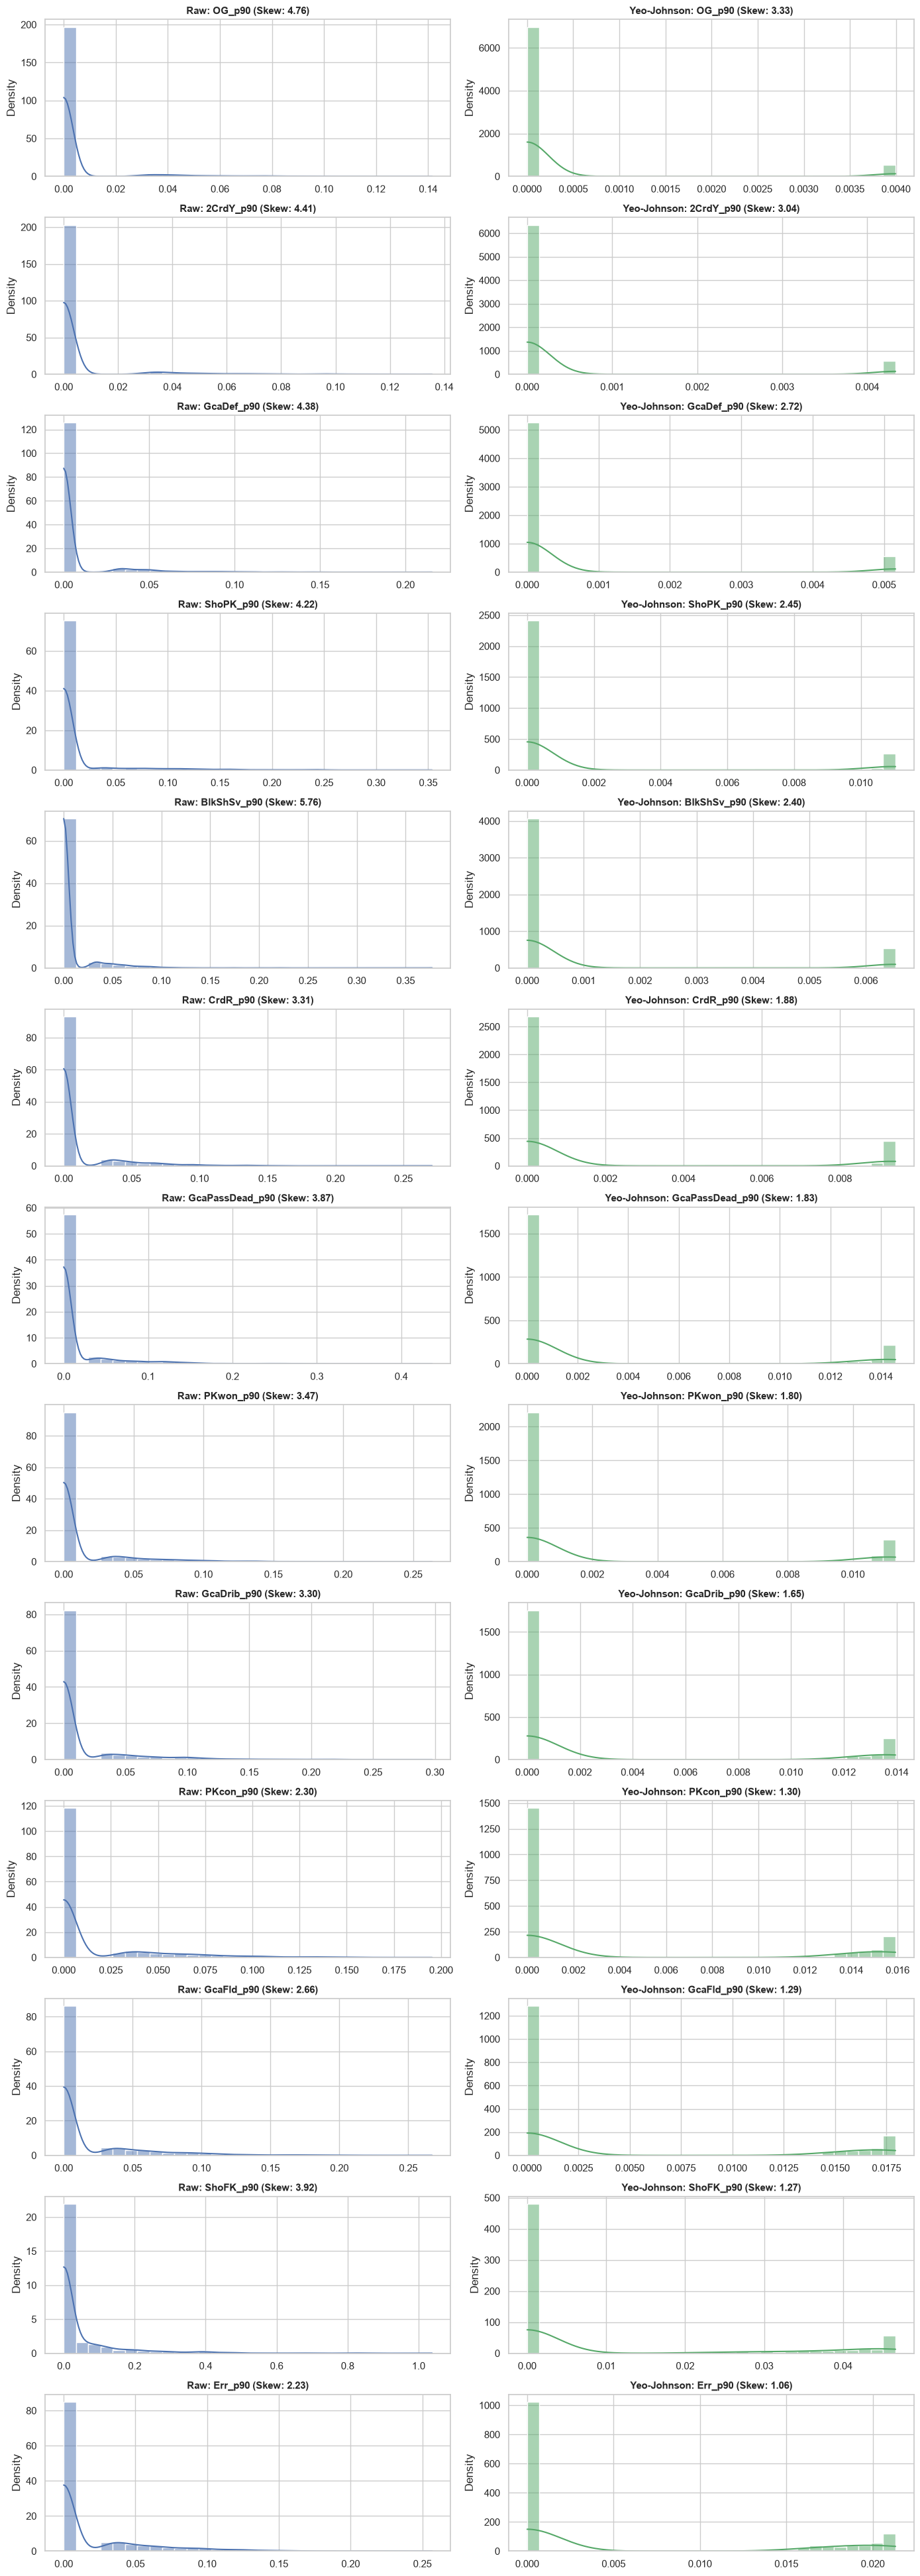

In [18]:
# Compare distribution before and after transformation
fig, axes = plt.subplots(len(still_skewed_features), 2, figsize=(14, 3 * len(still_skewed_features)))

for i, col in enumerate(still_skewed_features):
    raw_s = X_raw[col].skew()
    trans_s = X_transformed[col].skew()

    sns.histplot(X_raw[col], kde=True, color='#4C72B0', ax=axes[i, 0], stat='density', bins=30)
    axes[i, 0].set_title(f"Raw: {col} (Skew: {raw_s:.2f})", fontweight='bold', fontsize=11)
    axes[i, 0].set_xlabel('')

    sns.histplot(X_transformed[col], kde=True, color='#55A868', ax=axes[i, 1], stat='density', bins=30)
    axes[i, 1].set_title(f"Yeo-Johnson: {col} (Skew: {trans_s:.2f})", fontweight='bold', fontsize=11)
    axes[i, 1].set_xlabel('')

plt.tight_layout()
plt.show()


Even after transformation, 13 columns are still heavily skewed by zero-inflation in metrics relating to uncommon actions. If left as-is, these values are likely to dominate any dimension reduction and clustering.

There are several strategies we can use to address this:
- Weighting can be applied to dampen the possible spread of a high-variance metric, such as errors, penalties conceded, or blocked shots.
- For very rare metrics (e.g. own goals), we may want to remove these; with the justification that a season or two of data is unlikely to be a high enough sample (compared to the very low counts) to determine a repeated pattern vs random events.
- Depending on the metric meaning, we could categorise into True/False (1/0) features, representing whether the player performed that action **at all** (e.g. are they a penalty taker)
- Aggregate related, low-count features (such as yellow and red cards).

It is also worth noting that many of these may only be zero-inflated across all positions; e.g. BlkShSv_p90 (number of goal-bound shots blocked per 90) is likely to be far more common among defenders than all positions. This means a stratified, per-position pipeline may well handle these much better. However, with the issue of limited positional data (already highlighted in the EDA), this will be left for a v2 of this project. This is to prevent a player who plays multiple position from skewing the data, by bleeding across positions (e.g. a player who plays as a defender as well as a forward is likely to have much higher attacking metrics than one who has only played as a defender).

---

Of these remaining features, two are related to red cards (`2CrdY_p90` and `CrdR_p90`). A weighted sum of these and yellow cards - weighted using the UEFA Fair Play calculation weighting (3 points for a red, 1 for a yellow) - to account for the increased impact of a red versus a yellow card) will reduce this zero-inflation, as yellow cards are far more common.

As discussed in the EDA, `ShoPK_p90` and `ShoFK_p90` ony give an indication of whether the player is trusted to take these set pieces, rather than how successful they are from them. These can instead be converted to binary faetures, representing attacking set piece takers (after first assigning a lower boundary).

Own goals are very rare, and are unlikely to be statistically significant over just one season of data; these will therefore be dropped from the model.

Err_p90 and PKcon_p90 are both key defensive statistics, however do not truely reflect the player's 'style', and is as much of a product of the team around them as their archetype. As they are heavily zero-inflated, they will be dampened as above, Again though, these are likely to be a prime contender to be included in a future defenders-only stratification of the  model.

GcaDrib, GcaFld, and GcaDef, GcaPassDead_p90 are all related to goals created from dribbles, being fouled, defensive actions, and set piece passes, respectively. However, their signal is already largely captured by the 'Sca' equivalents, which relate to shots created instead, as well as the broader GCA_p90. This can therefore be dropped, with the Sca equivalents retained, with the further justification that the conversion of a shot created to a goal is not necessarily reflective of the player themselves. These again will likely be more effective in the future stratified model.

Similarly, BlkShSv_p90 is largely covered by BlkSh_p90, Blocks_p90, and Clr_p9; behaviours/ability leading to Err_p90 is covered by `CarMis_p90`, `CarDis_p90`, `PasPress_p90`, & `TouDefPen_p90; and PKcon_p90 is covered by `Fls_p90`, `TklDriPast_p90`, & `TklDri%`. Furthermore, these are primarily isolated to defenders. PKwon_p90 will be largely covered by CPA_p90, TouAttPen_p90, and ScaFld_p90. and is primarily isolated to forwards.

These will therefore be dropped for now, but re-explored in the stratified model.

In summary:

   | Feature | Raw Zero % | Planned Action                       | Replacement / Signal Retention | Strategic Rationale |
   | :--- | :--- |:-------------------------------------| :--- | :--- |
   | `2CrdY_p90` | 99.5% | **Aggregate $\rightarrow$ Metadata** | Combined into `card_points_p90` | Red cards are rare; aggregating with yellow cards via the UEFA Fair Play weighting (1 pt yellow, 3 pts red) reduces zero inflation from ~99% down to ~6%. |
   | `CrdR_p90` | 99.1% | **Aggregate $\rightarrow$ Metadata** | Combined into `card_points_p90` | Subsumed into the weighted discipline score; moved to metadata. |
   | `ShoPK_p90` | 88.7% | **Binarise $\rightarrow$ Metadata**  | Binary feature: `is_pk_taker` | Penalty volume reflects coach designation rather than technique; binary indicator isolates the attacking role without skewing distances. |
   | `ShoFK_p90` | 74.7% | **Binarise $\rightarrow$ Metadata**  | Binary feature: `is_fk_taker` | Isolates direct free kick takers as a discrete profile attribute. |
   | `OG_p90` | 92.9% | **Drop $\rightarrow$ Metadata**      | Dropped from modelling | Stochastic noise over a single season; deflections and bad bounces do not define player archetype. |
   | `Err_p90` | 72.8% | **Drop $\rightarrow$ Metadata**      | Covered by `CarMis_p90`, `CarDis_p90`, `PasPress_p90`, & `TouDefPen_p90` | Unforced mistakes leading to shots are rare event outcomes. Underlying ball security, turnover rates under pressure, and deep pitch occupancy are already captured by high-frequency continuous metrics. |
   | `PKcon_p90` | 77.0% | **Drop $\rightarrow$ Metadata**      | Covered by `Fls_p90`, `card_points_p90`, `TklDriPast_p90`, & `TklDri%` | Rare box foul heavily dependent on referee/team siege context. A defender's rashness and 1v1 vulnerability are already consistently captured by foul rates, cards, and times dribbled past. |
   | `GcaDef_p90` | 90.3% | **Drop $\rightarrow$ Metadata**      | Covered by `ScaDef_p90` & `GCA_p90` | Goal conversion depends on teammate finishing; shot-creating defensive actions (`ScaDef_p90`, 43% zeros) provide a far more robust stylistic signal. |
   | `GcaPassDead_p90` | 83.6% | **Drop $\rightarrow$ Metadata**      | Covered by `CK_p90`, `ShoFK_p90`, & dead-ball SCA | Rare-event deliveries resulting directly in goals; better evaluated in a specialized set-piece subset. |
   | `GcaDrib_p90` | 81.7% | **Drop $\rightarrow$ Metadata**      | Covered by `ScaDrib_p90` & `GCA_p90` | Dribble-to-goal events are low-sample; `ScaDrib_p90` (40% zeros) captures 1v1 creation skill cleanly. |
   | `GcaFld_p90` | 76.8% | **Drop $\rightarrow$ Metadata**      | Covered by `ScaFld_p90` & `GCA_p90` | Fouls leading directly to goals are rare; `ScaFld_p90` (34% zeros) captures high-leverage foul drawing. |
   | `BlkShSv_p90` | 88.4% | **Drop $\rightarrow$ Metadata**      | Covered by `BlkSh_p90`, `Blocks_p90`, `Clr_p90` | Goal-line clearances are isolated to deep-block centre-backs; general shot blocking and clearances already capture this profile. |
   | `PKwon_p90` | 83.4% | **Drop $\rightarrow$ Metadata**      | Covered by `CPA_p90`, `TouAttPen_p90`, `ScaFld_p90` | Rare single-season event; underlying traits are penalty box touches/carries and fouls drawn in the final third. |

In [19]:
# UEFA Fair Play calculation: 1 pt for Yellow, 3 pts for Red
card_points_raw = X_raw['CrdY_p90'] + (3.0 * X_raw['CrdR_p90'])
pt_cards = PowerTransformer(method='yeo-johnson', standardize=False)
X_transformed['card_points_p90'] = pt_cards.fit_transform(card_points_raw.to_frame()).flatten()

# Convert penalty and free kick shots to binary pk/fk_takers.
# Is True if a player has taken at least one shot, AND is among the highest 50% percentile per game
# among those who have taken at a shot
# this is to filter out one-off and occasional free kick takters
PK_TAKER_PCT = 50
FK_TAKER_PCT = 50

pk_takers = X_raw.loc[X_raw['ShoPK_p90'] > 0, 'ShoPK_p90']
fk_takers = X_raw.loc[X_raw['ShoFK_p90'] > 0, 'ShoFK_p90']

pk_threshold = np.percentile(pk_takers, PK_TAKER_PCT)
fk_threshold = np.percentile(fk_takers, FK_TAKER_PCT)

X_transformed['is_pk_taker'] = (X_raw['ShoPK_p90'] >= pk_threshold).astype(int)
X_transformed['is_fk_taker'] = (X_raw['ShoFK_p90'] >= fk_threshold).astype(int)

print(f"PK Taker Threshold: >= {pk_threshold:.4f} p90 ({X_transformed['is_pk_taker'].sum()} players qualified)")
print(f"FK Taker Threshold: >= {fk_threshold:.4f} p90 ({X_transformed['is_fk_taker'].sum()} players qualified)")

# Move the others to meta data, no longer to be used in modelling

COLS_TO_METADATA = [
   # Card components subsumed into card_points_p90
   'CrdY_p90', 'CrdR_p90', '2CrdY_p90',
   # Set-piece raw volume converted to binary indicators
   'ShoPK_p90', 'ShoFK_p90',
   # Stochastic noise over 1 season
   'OG_p90',
   # Negative outcomes covered by continuous ball security & foul/duel rates
   'Err_p90', 'PKcon_p90',
   # Goal-creating components covered by Sca equivalents & broader GCA
   'GcaDef_p90', 'GcaPassDead_p90', 'GcaDrib_p90', 'GcaFld_p90',
   # Positional extreme outliers covered by clearances/blocks and box entries
   'BlkShSv_p90', 'PKwon_p90',
]

# Move raw values to metadata_df
for col in COLS_TO_METADATA:
   if col in X_raw.columns and col not in metadata_df.columns:
       metadata_df[col] = X_raw[col]

# Drop from the active modelling feature matrix
X_transformed = X_transformed.drop(columns=[col for col in COLS_TO_METADATA if col in X_transformed.columns])

PK Taker Threshold: >= 0.0847 p90 (98 players qualified)
FK Taker Threshold: >= 0.1154 p90 (220 players qualified)


In [21]:
print("\n=== Feature Space Update Complete ===")
print(f"X_transformed shape: {X_transformed.shape} ({len(X_transformed.columns)} modelling features)")
print(f"metadata_df shape:   {metadata_df.shape} ({len(metadata_df.columns)} metadata columns)")


=== Feature Space Update Complete ===
X_transformed shape: (1737, 99) (99 modelling features)
metadata_df shape:   (1737, 24) (24 metadata columns)


## Scaling

The data is in different units (ratio, per90 averages, bounded percentages, binary flags, etc), and therefore needs scaling before dimension reductiona and cluster analysis.

There are two main methods available:
- StandardScaler: Centres on the mean and scales to variance ($\sigma = 1.0$).
- RobustScaler: Centers by the median and divides by IQR ($Q_3 - Q_1$).

As some of our data is still fairly zero inflated, $Q_3 - Q_1$ will equal 0, resulting in no scaling being applied (as per the `RobustScaler` documentation). Therefore StandardScaler is more appropriate.

In [22]:
def scale_features(
    X: pd.DataFrame,
    scaler_type: str = 'standard',
) -> tuple[pd.DataFrame, StandardScaler | RobustScaler]:
    """Scales numeric features using StandardScaler or RobustScaler."""
    if scaler_type == 'standard':
        scaler = StandardScaler()
    elif scaler_type == 'robust':
        scaler = RobustScaler()
    else:
        raise ValueError(f"Unsupported scaler_type: {scaler_type}. Use 'standard' or 'robust'.")

    scaled_vals = scaler.fit_transform(X)
    X_scaled = pd.DataFrame(scaled_vals, index=X.index, columns=X.columns)
    return X_scaled, scaler


X_std_scaled, std_scaler = scale_features(X_transformed, scaler_type='standard')
X_rob_scaled, rob_scaler = scale_features(X_transformed, scaler_type='robust')

iqr_vals = X_rob_scaled.quantile(0.75) - X_rob_scaled.quantile(0.25)
zero_iqr_features = iqr_vals[iqr_vals == 0].index.tolist()

print("=== Scaler Comparison ===")
print(f"StandardScaler Mean range:   [{X_std_scaled.mean().min():.2e}, {X_std_scaled.mean().max():.2e}]")
print(f"StandardScaler Std range:    [{X_std_scaled.std().min():.4f}, {X_std_scaled.std().max():.4f}]")
print(f"RobustScaler Median range:   [{X_rob_scaled.median().min():.2f}, {X_rob_scaled.median().max():.2f}]")
print(f"Features with IQR == 0 in RobustScaler: {len(zero_iqr_features)} (e.g. {zero_iqr_features[:4]})")


=== Scaler Comparison ===
StandardScaler Mean range:   [-7.01e-16, 1.40e-15]
StandardScaler Std range:    [1.0003, 1.0003]
RobustScaler Median range:   [0.00, 0.00]
Features with IQR == 0 in RobustScaler: 2 (e.g. ['is_pk_taker', 'is_fk_taker'])


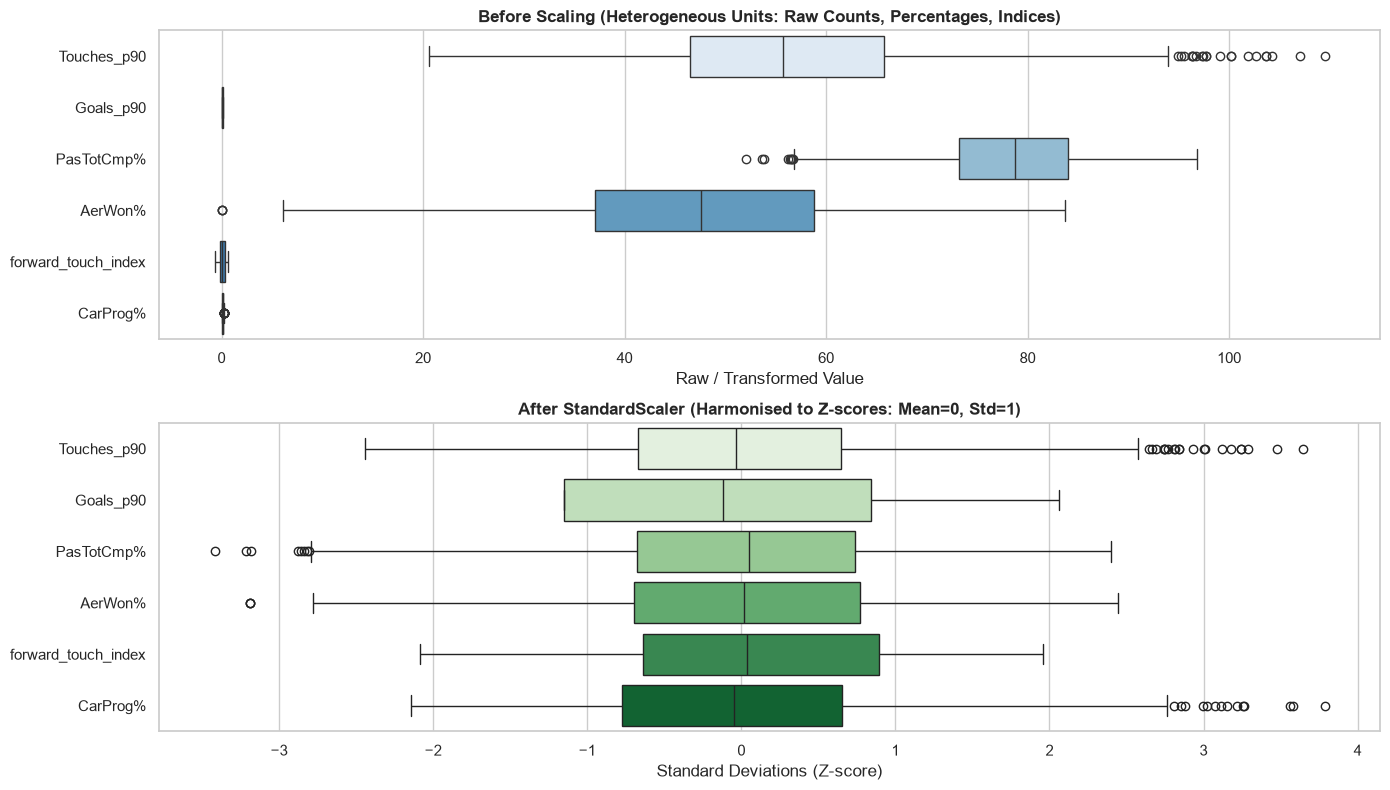

In [23]:
sample_diverse_metrics = [
    'Touches_p90',          # High-volume count
    'Goals_p90',            # Low-volume count
    'PasTotCmp%',           # Percentage
    'AerWon%',              # Percentage
    'forward_touch_index',  # Spatial index
    'CarProg%',             # Progression ratio
]

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

# Before scaling
sns.boxplot(data=X_transformed[sample_diverse_metrics], orient='h', palette='Blues', ax=axes[0])
axes[0].set_title('Before Scaling (Heterogeneous Units: Raw Counts, Percentages, Indices)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Raw / Transformed Value')

# After StandardScaler
sns.boxplot(data=X_std_scaled[sample_diverse_metrics], orient='h', palette='Greens', ax=axes[1])
axes[1].set_title('After StandardScaler (Harmonised to Z-scores: Mean=0, Std=1)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Standard Deviations (Z-score)')

plt.tight_layout()
plt.show()


## Summary & Next Steps (Milestone 3.2)

This notebook explored:
- Modelling Feature Split: features unsuitable for modelling are split from those that are; e.g. contextual features (age, position, club, etc)
- Skew Analysis: analyse the modelling featureset for skew and non-normal distributions.
- Skew & Sparsity Engineering: transform highly skewed features, and handle sparse features via aggregation, new feature engineering, and pruning.
- Scaling: scale the featureset, ready for dimension reduction and clustering.

Next steps:
The data has been transformed and scaled, and is now ready for dimension reduction and cluster analysis.
The next steps are to explore this dimension reduction, and then develop a clustering model.
